# 09 — Daily forecasting: consolidated results and model decision

**Carry forward the tuned 61-source-feature LightGBM as the daily stock-level auction-volume forecast.** Keep the compact global ridge as the linear benchmark. Retain event inputs as a promising extension and Tweedie as a candidate for a separately defined daily-total objective.

This notebook consolidates notebooks 01–08. It does not train new challengers or change earlier selection rules. It rebuilds an annual results ledger from the saved studies, checks summary arithmetic, independently scores the available fresh booster and frozen ridge forecasts, and distinguishes complete historical results from worked one-year fits.

Published tuned LightGBM development log RMSE is **0.46357**, stock WAPE **34.88%**, and 2025 confirmation log RMSE **0.42417**. Its fresh four-fold reference refit scores **0.46402**, **34.86%** and **0.42224**, respectively. These are separate runs of the same selected recipe.

Read this notebook as a sequence of matched experiments. Sample sizes, preprocessing and historical references differ across studies, so a single numerical ranking across every row would overstate comparability. All figures and tables are embedded. New summary artifacts are written to `outputs/experiments/31_daily_model_summary`.

In [1]:
from pathlib import Path
import json,hashlib,sys
from datetime import datetime,timezone
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=next(p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'blackrock_data').is_dir())
OUT=ROOT/'outputs';RUN=OUT/'experiments/31_daily_model_summary';RUN.mkdir(parents=True,exist_ok=True)
DEV=[2022,2023,2024];YEARS=[2022,2023,2024,2025]
RIDGE='rolling5_residual_auction_calendar_liquidity';TUNED='lgbm_61_ratios_large_tuned'
pd.set_option('display.max_columns',14);pd.set_option('display.max_rows',85)
pd.set_option('display.float_format',lambda x:f'{x:,.6f}')
sns.set_theme(style='whitegrid',palette='colorblind');plt.rcParams.update({'figure.dpi':110})
con=duckdb.connect(config={'threads':4})
source_paths=[]
def read(path):
    full=OUT/path;source_paths.append(full);return pd.read_csv(full)
def file_hash(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
    return h.hexdigest()
def forecast_scores(actual,pred):
    actual=np.asarray(actual,float);pred=np.asarray(pred,float)
    assert np.isfinite(actual).all() and np.isfinite(pred).all() and (pred>=0).all()
    return {'observations':len(actual),'rmse_log':np.mean((np.log1p(pred)-np.log1p(actual))**2)**.5,
            'wape':np.abs(pred-actual).sum()/actual.sum(),'aggregate_bias':pred.sum()/actual.sum()-1}

## Target, information timing and evaluation

The selected target is $r_t=\log(1+A_t)-\log(1+M_{20,t})$, with $M_{20,t}$ the stock's trailing median over prior observations. The median is a strong historical scale reference. The alternative lag-one log-growth target remained a useful finalist, but did not establish a replacement in the matched ridge comparison. This research establishes the empirical benchmark; a claim about industry-wide practice would require separate external evidence.

Daily inputs use information available by the preceding close, plus known calendar fields. Historical stock histories update during a forecast year, while the fitted preprocessing and model parameters stay fixed for that annual fold. No current-session intraday data enter these daily forecasts.

For evaluation year Y, tune on Y−6 through Y−2, validate on Y−1, and refit on Y−5 through Y−1. The large tree tier uses caps of 750,000 tuning, 150,000 validation and 1,000,000 refit stock-days. Smaller historical studies use their own documented caps. All 2022–2025 eligible test rows are retained in the main model studies; early baselines have different coverage, which is shown explicitly.

| Measure | Role |
| --- | --- |
| Log RMSE: root mean squared difference of `log1p` forecasts and labels | Primary stock-level selection score; penalizes large proportional misses |
| Stock WAPE: sum of absolute share errors / observed shares | Absolute share accuracy; large auctions contribute more |
| Log MAE and paired daily log-MAE differences | Typical proportional error and the original paired replacement check |
| Aggregate bias: predicted shares / observed shares − 1 | Total-share under- or overprediction; errors can cancel |
| Daily-total WAPE | Error after summing stocks within each session; a distinct aggregate objective |
| Coverage and Spearman | Serving the universe and ranking stock-days; neither substitutes for error accuracy |

Development metrics average the three annual 2022–2024 scores equally, rather than pooling every stock-day or averaging daily WAPEs. The previously inspected 2025 year is retrospective confirmation, not a new untouched test.

In [2]:
# Normalise annual files, preserving the study and candidate identifiers.
parts=[]
def add(cohort,path,candidate='candidate',year='test_year',filters=None,rename=None,evidence='saved study'):
    frame=read(path)
    if filters is not None:frame=filters(frame)
    frame=frame.rename(columns={candidate:'candidate',year:'year',**(rename or {})})
    columns=['year','candidate','observations','rmse_log','wape','aggregate_bias']
    assert not frame.duplicated(['year','candidate']).any(),cohort
    frame=frame[columns].copy();frame['cohort']=cohort;frame['evidence']=evidence
    frame['source']=path;parts.append(frame)
add('Historical baselines','eda/07_temporal_baselines/overall_baseline_metrics.csv',candidate='model')
add('Target and feature finalists','experiments/22_full_feature_ridge_growth/annual_metrics.csv',candidate='model',year='year')
add('Global ridge finalists','eda/09_global_finalists/global_finalist_metrics.csv')
add('Ridge segmentation','eda/10_segmentation_tests/segmentation_candidate_metrics.csv')
add('Verified compact nonlinear','reproduction/03_compact_nonlinear/nonlinear_candidate_metrics.csv',evidence='saved models reconstructed in notebook 05')
add('Original expanded nonlinear','eda/16_nonlinear_challengers/nonlinear_candidate_metrics.csv',
    filters=lambda f:f[f.candidate.str.contains('99')])
add('LightGBM improvement series','eda/16a_lightgbm_improvements/candidate_metrics.csv')
add('Historical CatBoost','eda/16b_catboost_challenger/candidate_metrics.csv')
add('Fresh booster comparison','experiments/28_daily_booster_comparison/annual_metrics.csv',candidate='family',year='year',evidence='fresh four-fold fits in notebook 06')
add('HMM and regime inputs','eda/16d_hmm_regime_features/candidate_metrics.csv')
add('Neural networks and blend','eda/16e_sequence_neural_networks/candidate_metrics.csv')
add('Spline and tail audit','experiments/30_checkpoint5_master_audit/reconstructed_metrics.csv',year='year',evidence='saved models reconstructed in notebook 08')
add('Loss and event comparison','experiments/30_checkpoint5_master_audit/verified_tweedie_annual_metrics.csv',candidate='model',year='year',
    filters=lambda f:f[f.segment.eq('all')],rename={'rows':'observations','log_rmse':'rmse_log','share_wape':'wape','share_bias':'aggregate_bias'},
    evidence='saved forecasts independently scored in notebook 08')
annual=pd.concat(parts,ignore_index=True)
assert not annual.duplicated(['cohort','candidate','year']).any()
assert set(annual.year)==set(YEARS)
assert annual.groupby(['cohort','candidate']).year.nunique().eq(4).all()
assert np.isfinite(annual[['observations','rmse_log','wape','aggregate_bias']]).all().all()
assert (annual[['observations','rmse_log','wape']]>=0).all().all()
summary=annual[annual.year.isin(DEV)].groupby(['cohort','candidate']).agg(
    development_log_RMSE=('rmse_log','mean'),development_WAPE=('wape','mean'),development_bias=('aggregate_bias','mean'))
confirmation=annual[annual.year.eq(2025)].set_index(['cohort','candidate'])
summary['2025_log_RMSE']=confirmation.rmse_log;summary['2025_WAPE']=confirmation.wape
summary['2025_bias']=confirmation.aggregate_bias
annual.to_csv(RUN/'annual_results_ledger.csv',index=False);summary.to_csv(RUN/'development_and_confirmation.csv')
display(annual.groupby('cohort').agg(candidates=('candidate','nunique'),annual_rows=('year','size')))
print(f'{len(summary)} study/candidate entries across {len(parts)} cohorts; repeated references retain their provenance.')

,candidates,annual_rows
cohort,,
Fresh booster comparison,3,12
Global ridge finalists,7,28
HMM and regime inputs,6,24
Historical CatBoost,2,8
Historical baselines,8,32
LightGBM improvement series,6,24
Loss and event comparison,5,20
Neural networks and blend,7,28
Original expanded nonlinear,2,8


72 study/candidate entries across 13 cohorts; repeated references retain their provenance.


## From historical rules to the compact global ridge

Notebook 04 tested historical volume rules, targets, rolling/expanding windows, weighting, source groups and segmentation. The selected ridge uses 58 sources: 19 auction-history, 23 calendar and 16 liquidity fields, with uniform weights and a five-year rolling fit. Its development log RMSE is approximately 0.48764.

The recently weighted 99-source ridge scores approximately 0.48677. The 0.00088 difference falls inside the practical tie range, so the compact specification remains the linear reference. Size segmentation reaches approximately 0.48648, a gain of 0.00116 against the compact reference. It fails the recorded replacement conditions.

Independent fits by size, liquidity, auction intensity and size × liquidity, pooled interactions, event specialists and short-history specialists were all explored. Small overall gains and mixed subgroup evidence did not justify replacing the pooled model. Segments remain useful for error diagnostics and for explicitly different subgroup objectives.

In [3]:
baseline=read('eda/07_temporal_baselines/overall_baseline_metrics.csv')
baseline_summary=summary.loc['Historical baselines'].copy()
baseline_summary['development_coverage']=baseline[baseline.test_year.isin(DEV)].groupby('model').coverage.mean()
display(baseline_summary)
display(summary.loc['Target and feature finalists'])
display(summary.loc['Global ridge finalists'].sort_values('development_log_RMSE'))
segmentation=read('eda/10_segmentation_tests/segmentation_decision_table.csv')
assert not segmentation.eligible_general_replacement.any()
display(segmentation[['candidate','development_rmse_log','development_wape','rmse_change_vs_frozen',
                     'ci_97_5','eligible_general_replacement']])

,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias,development_coverage
candidate,,,,,,,
auction_participation_x_adv,0.712123,0.502350,-0.038066,0.592914,0.449190,-0.003874,0.999365
avg5_auction,0.698254,0.566478,-0.002836,0.605315,0.487429,-0.004120,0.998119
global_ridge,0.500395,0.375303,-0.142445,0.451384,0.350386,-0.116223,1.000000
global_ridge_calibrated,0.534694,0.430800,0.043677,0.479433,0.397128,0.053465,1.000000
lag1_auction,0.713920,0.622612,-0.002268,0.633512,0.543853,-0.003457,1.000000
median20_auction,0.609193,0.434375,-0.247274,0.538260,0.393095,-0.200759,0.999365
median20_fallback,0.621136,0.434678,-0.247421,0.540633,0.393229,-0.200896,1.000000
median60_auction,0.628726,0.436014,-0.268510,0.558289,0.396787,-0.224990,0.999746


,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
candidate,,,,,,
compact58_log_growth,0.490984,0.374289,-0.148009,0.448604,0.349991,-0.104959
compact58_median20,0.488111,0.367422,-0.145020,0.446653,0.345025,-0.097314
frozen_compact58_median20,0.487643,0.368007,-0.143778,0.445119,0.345631,-0.096235
full99_log_growth,0.490487,0.373977,-0.142797,0.451465,0.347100,-0.137548
full99_median20,0.487828,0.366631,-0.144833,0.449556,0.341431,-0.130194


,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
candidate,,,,,,
rolling5_residual_recent_full,0.486765,0.367338,-0.139811,0.446137,0.341421,-0.126070
rolling5_residual_full,0.487103,0.366901,-0.143794,0.450133,0.341316,-0.141464
rolling5_residual_auction_calendar_liquidity,0.487643,0.368007,-0.143778,0.445119,0.345631,-0.096235
rolling5_residual_auction_calendar,0.490588,0.369037,-0.139760,0.447855,0.347343,-0.091526
rolling3_residual_full,0.492203,0.367439,-0.140161,0.448934,0.341303,-0.135193
rolling5_log_full,0.496092,0.371661,-0.143689,0.453207,0.346264,-0.152296
expanding_log_full,0.498977,0.376744,-0.136761,0.451175,0.353281,-0.110544


,candidate,development_rmse_log,development_wape,rmse_change_vs_frozen,ci_97_5,eligible_general_replacement
0,split_size,0.486480,0.364146,-0.001162,0.000129,False
1,split_size_liquidity_2x2,0.486728,0.364328,-0.000914,0.000133,False
2,rolling5_residual_recent_full,0.486765,0.367338,-0.000877,0.000821,False
3,split_intensity,0.487221,0.368213,-0.000422,0.000659,False
4,interaction_size,0.487434,0.365910,-0.000209,0.000108,False
5,interaction_intensity,0.487508,0.368094,-0.000135,0.000595,False
6,rolling5_residual_auction_calendar_liquidity,0.487643,0.368007,0.000000,NaN,False
7,split_liquidity,0.487673,0.365734,0.000030,0.000321,False
8,interaction_liquidity,0.487864,0.366078,0.000221,0.000069,False
9,history_hybrid,0.487961,0.367001,0.000318,0.000320,False


## How the daily LightGBM champion was reached

The final recipe keeps the median-relative log target and adds three explicit logged volume ratios to the compact 58 sources: lag-one auction / median20, average-five auction / median20, and lag-one auction / median60. These are 61 **source features**, before any encoded columns and missing indicators.

The study first adds the ratios, then expands historical sample sizes, then searches eight complexity and regularisation configurations. Configurations are selected separately using each fold's historical validation year. There is no single parameter configuration selected on all test years. Squared-error trees, Huber loss, ridge–tree blends, 99-source trees and linear leaves were also explored. The complete improvement series has its own matched 58-source control, whose score differs from the earlier verified compact model.

The combined improvement over that matched control is approximately 0.00897 development log RMSE. Larger samples supply the largest step. Wider tuning contributes a smaller approximately 0.00184 improvement over the untuned large model. The recorded adoption gates compare the complete candidate with the matched control and ridge reference; they do not establish that every incremental step independently exceeds 0.002.

,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
candidate,,,,,,
lgbm_58_control,0.472539,0.355395,-0.174066,0.435001,0.333841,-0.076886
lgbm_61_ratios,0.470094,0.352647,-0.169889,0.428952,0.327987,-0.086039
lgbm_61_ratios_large,0.465409,0.350727,-0.147004,0.423634,0.323382,-0.098796
lgbm_61_ratios_large_tuned,0.463571,0.348804,-0.152247,0.424170,0.324364,-0.099150
lgbm_61_ratios_large_linear,0.474244,0.363401,-0.115773,0.425111,0.324038,-0.104655


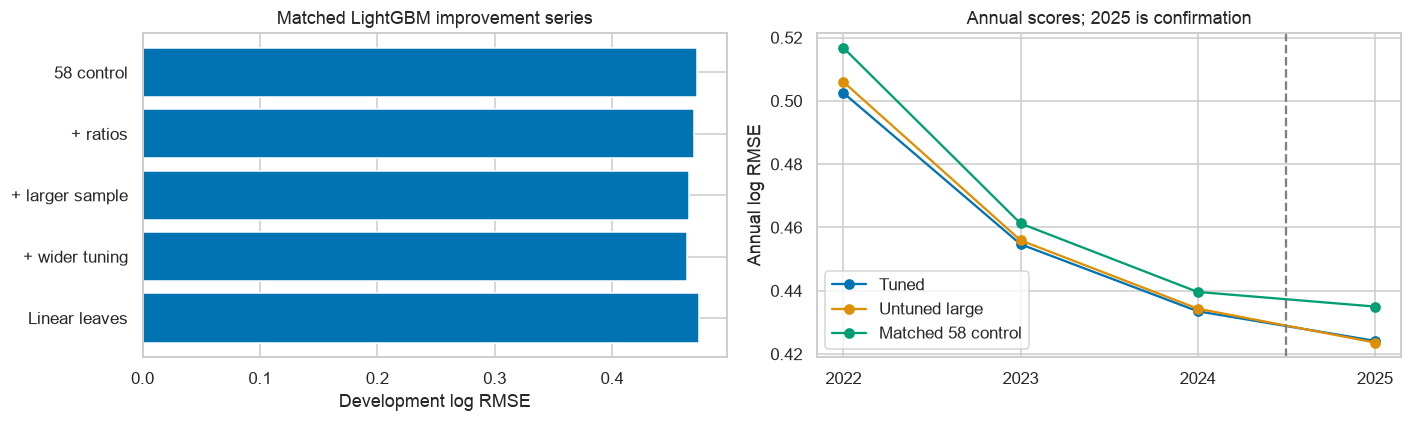

,config_id,best_iteration,validation_rmse_log,config
test_year,,,,
2022,0,671,0.569758,"{""colsample_bytree"": 0.7, ""learning_rate"": 0.0..."
2023,3,782,0.506081,"{""colsample_bytree"": 0.6, ""learning_rate"": 0.0..."
2024,3,959,0.454490,"{""colsample_bytree"": 0.6, ""learning_rate"": 0.0..."
2025,3,519,0.430227,"{""colsample_bytree"": 0.6, ""learning_rate"": 0.0..."


In [4]:
series=summary.loc['LightGBM improvement series'].drop(index=RIDGE)
order=['lgbm_58_control','lgbm_61_ratios','lgbm_61_ratios_large',TUNED,'lgbm_61_ratios_large_linear']
display(series.loc[order])
fig,axes=plt.subplots(1,2,figsize=(13,4))
labels=['58 control','+ ratios','+ larger sample','+ wider tuning','Linear leaves']
axes[0].barh(labels,series.loc[order].development_log_RMSE)
axes[0].set(xlabel='Development log RMSE',title='Matched LightGBM improvement series');axes[0].invert_yaxis()
source=annual[annual.cohort.eq('LightGBM improvement series')]
for name,label in [(TUNED,'Tuned'),('lgbm_61_ratios_large','Untuned large'),('lgbm_58_control','Matched 58 control')]:
    frame=source[source.candidate.eq(name)].sort_values('year')
    axes[1].plot(frame.year,frame.rmse_log,marker='o',label=label)
axes[1].axvline(2024.5,color='grey',linestyle='--');axes[1].set(xticks=YEARS,ylabel='Annual log RMSE',title='Annual scores; 2025 is confirmation');axes[1].legend()
plt.tight_layout();plt.show()
trials=read('eda/16a_lightgbm_improvements/hyperparameter_validation.csv')
trials=trials[trials.candidate.eq(TUNED)]
choices=trials.loc[trials.groupby('test_year').validation_rmse_log.idxmin()].sort_values('test_year')
assert len(choices)==4 and len(trials)==32
display(choices[['test_year','config_id','best_iteration','validation_rmse_log','config']].set_index('test_year'))
champion=summary.loc[('LightGBM improvement series',TUNED)]
np.testing.assert_allclose(champion.development_log_RMSE,0.46357074256,atol=1e-10)

## What the challenger families added

| Family | Main result | Interpretation |
| --- | --- | --- |
| CatBoost and XGBoost | Fresh CatBoost is almost tied in log RMSE but has worse WAPE; XGBoost is worse overall | Neither passes replacement conditions in the tested grids |
| HMM and direct regime inputs | Every saved augmentation trails the untuned large-tree control | Regime persistence does not establish incremental point-forecast value |
| MLP, CNN–LSTM sequence and hybrid networks | Individual networks trail tuned LightGBM | The tested architectures do not justify replacement |
| Fixed neural–tree blend | Development gain is about 0.00027; 2025 is stronger | Below the practical threshold, and the paired development interval includes zero |
| Cubic splines and stock residual effects | Log RMSE around 0.4853; stock effect adds little | Useful shape descriptions, lower point accuracy than the verified tree |
| Tail mixture | Log-space mean gains about 0.00090 against verified compact LightGBM | Useful spike-risk signal, insufficient overall point-score gain |
| Tweedie and event features | Events help matched log controls; Tweedie favors total shares over stock log accuracy | Keep the objective and the reference explicit |

These conclusions apply to the explored specifications and data. They do not rule out every possible neural architecture, regime definition or tuning search.

,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
candidate,,,,,,
catboost,0.463938,0.351548,-0.142793,0.423969,0.324294,-0.106611
lightgbm_reference,0.464023,0.348589,-0.152559,0.422244,0.323766,-0.089580
xgboost,0.466654,0.350978,-0.147010,0.426545,0.328656,-0.092430


,family,mean_log_RMSE_change,worst_annual_change,daily_log_MAE_change,legacy_log_MAE_lower,legacy_log_MAE_upper,practical_gain,annual_stability,paired_log_MAE_favorable,passes_gate
0,catboost,-0.000084,0.001711,0.001205,-0.000057,0.002380,False,True,False,False
1,xgboost,0.002632,0.007574,0.003184,0.001810,0.004490,False,False,False,False


,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
candidate,,,,,,
lgbm_control,0.465409,0.350727,-0.147004,0.423634,0.323382,-0.098796
lgbm_plus_hmm_bic,0.472108,0.354562,-0.149454,0.433272,0.331781,-0.094703
lgbm_plus_hmm_k3,0.467189,0.352367,-0.150568,0.436694,0.333627,-0.087502
lgbm_plus_inputs_and_hmm_bic,0.473038,0.356300,-0.148999,0.434167,0.335545,-0.072297
lgbm_plus_regime_inputs,0.469495,0.353927,-0.152183,0.435906,0.340109,-0.050452


,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
candidate,,,,,,
blend_hybrid_lgbm,0.463297,0.348469,-0.164481,0.418392,0.319738,-0.107561
lgbm_61_ratios_large,0.465409,0.350727,-0.147004,0.423634,0.323382,-0.098796
lgbm_61_ratios_large_tuned,0.463571,0.348804,-0.152247,0.424170,0.324364,-0.099150
nn_cnn_lstm_hybrid,0.478536,0.357818,-0.169100,0.424525,0.324018,-0.111164
nn_cnn_lstm_sequence,0.485090,0.369542,-0.111190,0.427720,0.326912,-0.112505
nn_mlp_tabular,0.470043,0.357204,-0.125849,0.424875,0.325198,-0.091994


,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
candidate,,,,,,
lgbm_residual_58_l2,0.469414,0.354518,-0.144042,0.430646,0.329428,-0.088980
spline_residual_58,0.485346,0.363603,-0.162439,0.445497,0.342618,-0.101149
spline_residual_58_stock_effect,0.485256,0.363263,-0.160882,0.445474,0.342549,-0.100050
tail_mixture_log_mean,0.468516,0.351427,-0.160799,0.428852,0.327278,-0.104115
tail_mixture_share_mean,0.482761,0.355396,-0.125989,0.431853,0.331692,-0.070977


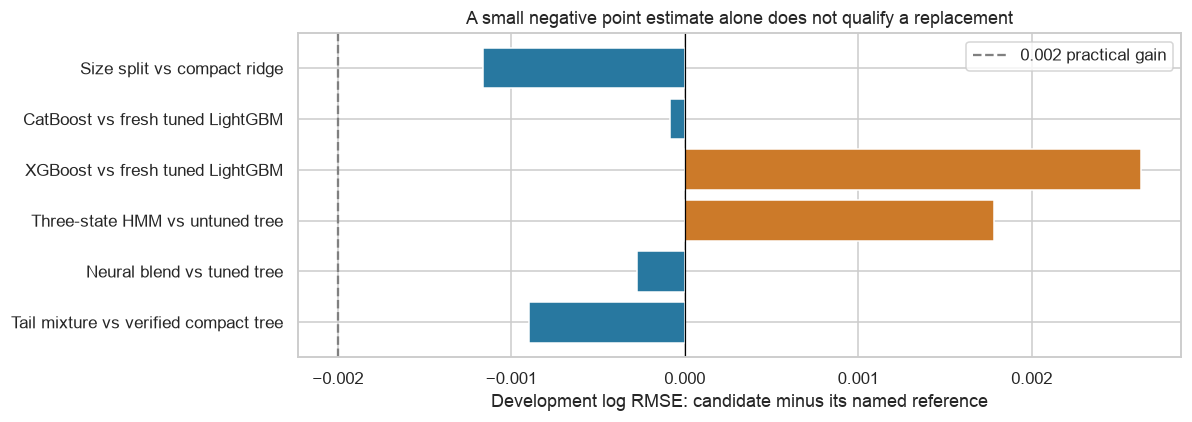

In [5]:
display(summary.loc['Fresh booster comparison'])
display(read('experiments/28_daily_booster_comparison/selection.csv'))
display(summary.loc['HMM and regime inputs'].drop(index=RIDGE))
display(summary.loc['Neural networks and blend'].drop(index=RIDGE))
display(summary.loc['Spline and tail audit'])
# Annual source scores, rather than a grand cross-study rank, drive each contrast.
contrasts=[
 ('Ridge segmentation','split_size',RIDGE,'Size split vs compact ridge'),
 ('Fresh booster comparison','catboost','lightgbm_reference','CatBoost vs fresh tuned LightGBM'),
 ('Fresh booster comparison','xgboost','lightgbm_reference','XGBoost vs fresh tuned LightGBM'),
 ('HMM and regime inputs','lgbm_plus_hmm_k3','lgbm_control','Three-state HMM vs untuned tree'),
 ('Neural networks and blend','blend_hybrid_lgbm',TUNED,'Neural blend vs tuned tree'),
 ('Spline and tail audit','tail_mixture_log_mean','lgbm_residual_58_l2','Tail mixture vs verified compact tree')]
rows=[]
for cohort,candidate,reference,label in contrasts:
    delta=summary.loc[(cohort,candidate),'development_log_RMSE']-summary.loc[(cohort,reference),'development_log_RMSE']
    rows.append({'comparison':label,'cohort':cohort,'candidate':candidate,'reference':reference,'development_log_RMSE_change':delta})
contrasts=pd.DataFrame(rows);contrasts.to_csv(RUN/'matched_contrasts.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4))
ax.barh(contrasts.comparison,contrasts.development_log_RMSE_change,color=['#2878a0' if x<0 else '#cc7a29' for x in contrasts.development_log_RMSE_change])
ax.axvline(0,color='black',linewidth=.8);ax.axvline(-.002,color='grey',linestyle='--',label='0.002 practical gain')
ax.set(xlabel='Development log RMSE: candidate minus its named reference',title='A small negative point estimate alone does not qualify a replacement')
ax.invert_yaxis();ax.legend();plt.tight_layout();plt.show()

## Replacement rules and uncertainty

The recurring rule requires development log-RMSE gain ≥0.002, no development year more than 0.002 worse, and a paired daily log-MAE interval with upper endpoint below zero. The segmentation study also compares the secondary global reference. Spline and tail studies additionally require no mean WAPE worsening. We preserve those differences.

A negative error difference is favorable, but a lower score alone does not satisfy the full rule. A smaller WAPE or better 2025 score also does not override the declared development criterion.

Most original interval files independently resample **whole single dates**, despite some filenames containing “block”. They retain stock dependence within a session, while omitting serial dependence across sessions. The fresh booster supplementary intervals use 20-session blocks and 5,000 draws; the Tweedie/event intervals use 20-session blocks and 4,000 draws. All condition on the fitted forecasts. None includes the uncertainty from refitting or repeated research choices. We do not pool their intervals into a common significance ranking.

In [6]:
gate_checks=[]
for study,path in [
 ('LightGBM improvement series','eda/16a_lightgbm_improvements/candidate_selection.csv'),
 ('HMM and regime inputs','eda/16d_hmm_regime_features/candidate_selection.csv'),
 ('Neural networks and blend','eda/16e_sequence_neural_networks/candidate_selection.csv')]:
    frame=read(path)
    metrics=summary.loc[study]
    source_annual=annual[annual.cohort.eq(study)].pivot(index='candidate',columns='year',values='rmse_log')
    for row in frame.itertuples():
        if row.candidate==row.reference:continue
        delta=metrics.loc[row.candidate,'development_log_RMSE']-metrics.loc[row.reference,'development_log_RMSE']
        worst=(source_annual.loc[row.candidate,DEV]-source_annual.loc[row.reference,DEV]).max()
        np.testing.assert_allclose([delta,worst],[row.rmse_change_vs_reference,row.worst_year_change],atol=1e-12)
        expected=bool(delta<=-.002 and worst<=.002 and row.log_mae_ci_97_5<0)
        assert str(row.passes_gate).lower()==str(expected).lower()
        gate_checks.append({'study':study,'candidate':row.candidate,'reference':row.reference,'passes_gate':expected})
gate_checks=pd.DataFrame(gate_checks);gate_checks.to_csv(RUN/'source_gate_checks.csv',index=False)
display(gate_checks)
display(read('experiments/28_daily_booster_comparison/paired_intervals.csv'))

,study,candidate,reference,passes_gate
0,LightGBM improvement series,lgbm_58_control,rolling5_residual_auction_calendar_liquidity,True
1,LightGBM improvement series,lgbm_61_ratios,rolling5_residual_auction_calendar_liquidity,True
2,LightGBM improvement series,lgbm_61_ratios_large,rolling5_residual_auction_calendar_liquidity,True
3,LightGBM improvement series,lgbm_61_ratios_large_tuned,rolling5_residual_auction_calendar_liquidity,True
4,LightGBM improvement series,lgbm_61_ratios_large_linear,rolling5_residual_auction_calendar_liquidity,False
5,LightGBM improvement series,lgbm_61_ratios,lgbm_58_control,True
6,LightGBM improvement series,lgbm_61_ratios_large,lgbm_58_control,True
7,LightGBM improvement series,lgbm_61_ratios_large_tuned,lgbm_58_control,True
8,LightGBM improvement series,lgbm_61_ratios_large_linear,lgbm_58_control,False
9,HMM and regime inputs,lgbm_plus_regime_inputs,lgbm_control,False


,family,period,metric,difference,ci_lower,ci_upper,block_dates,draws
0,catboost,development,log_RMSE,-0.000084,-0.001935,0.001525,20,5000
1,catboost,development,WAPE,0.002959,0.001338,0.004552,20,5000
2,catboost,confirmation,log_RMSE,0.001725,-0.000613,0.004230,20,5000
3,catboost,confirmation,WAPE,0.000528,-0.002097,0.003479,20,5000
4,xgboost,development,log_RMSE,0.002632,0.000651,0.004789,20,5000
5,xgboost,development,WAPE,0.002389,0.001226,0.003623,20,5000
6,xgboost,confirmation,log_RMSE,0.004301,0.000458,0.008185,20,5000
7,xgboost,confirmation,WAPE,0.004889,0.000949,0.008752,20,5000


## Stock accuracy, event response and daily totals

The event experiment uses a fresh four-way log/Tweedie × base/event comparison around the earlier compact sources. Its fitting caps differ from the champion study. Event inputs represent the scheduled Russell close, historical event lift, history count and stock size. They exclude the current event's outcome and use only earlier event observations.

Log plus events improves development log RMSE by about 0.00314 over its matched log control. That is promising evidence for a champion extension, but is not a measured improvement over the tuned 61-source model. The Russell-date result covers only three development dates.

Tweedie plus events achieves daily-total WAPE about 13.45%, versus 17.59% for log plus events, while stock WAPE rises from about 35.25% to 37.58%. Its stock-level log RMSE is about 0.518. The aggregate objective benefits from cross-stock error cancellation and a different loss. Keep it separate from the daily stock-level champion decision.

,log_rmse,share_wape,daily_total_wape,share_bias
model,,,,
log_control,0.471092,0.354739,0.177923,-0.152526
log_events,0.467952,0.352542,0.175944,-0.153404
published_log,0.469414,0.354518,0.172538,-0.144042
tweedie,0.526199,0.377872,0.142074,-0.047375
tweedie_events,0.517700,0.375766,0.134538,-0.047423


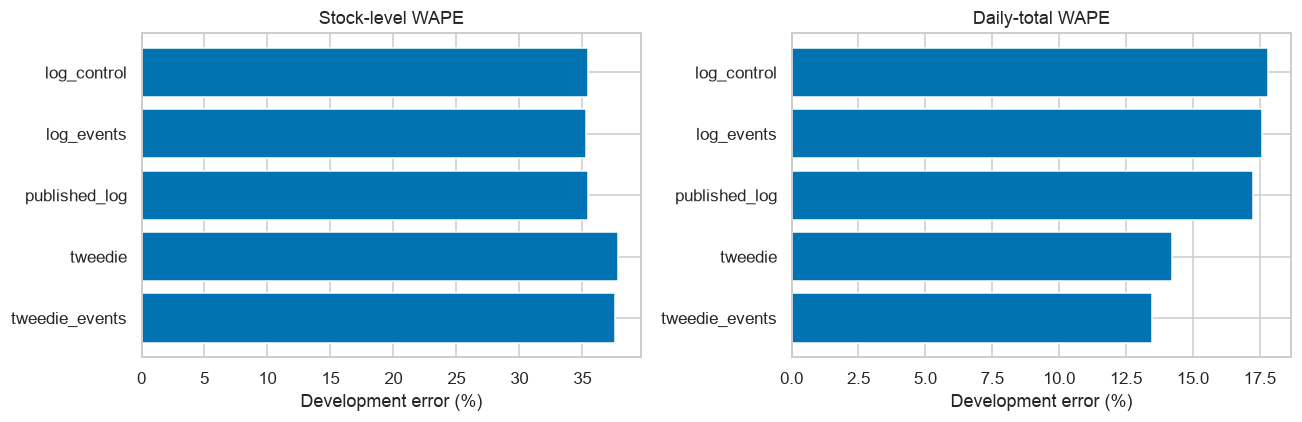

,model,control,metric,delta,lower_95,upper_95
0,log_events,log_control,log_rmse,-0.003140,-0.005954,-0.000990
1,log_events,log_control,share_wape,-0.002197,-0.004341,-0.000561
2,log_events,log_control,daily_total_wape,-0.001979,-0.007321,0.002754
3,log_events,log_control,share_bias,-0.000878,-0.005278,0.003415
4,tweedie,log_control,log_rmse,0.055107,0.050575,0.059865
5,tweedie,log_control,share_wape,0.023133,0.019775,0.026846
6,tweedie,log_control,daily_total_wape,-0.035849,-0.043224,-0.027108
7,tweedie,log_control,share_bias,0.105151,0.097908,0.112600
8,tweedie_events,log_control,log_rmse,0.046607,0.041683,0.051438
9,tweedie_events,log_control,share_wape,0.021027,0.017093,0.024678


In [7]:
loss=read('experiments/23_tweedie_and_rebalance/development_metrics.csv')
loss=loss[loss.segment.eq('all')].set_index('model')
display(loss[['log_rmse','share_wape','daily_total_wape','share_bias']])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,title in zip(axes,['share_wape','daily_total_wape'],['Stock-level WAPE','Daily-total WAPE']):
    ax.barh(loss.index,100*loss[metric]);ax.invert_yaxis();ax.set(title=title,xlabel='Development error (%)')
plt.tight_layout();plt.show()
display(read('experiments/23_tweedie_and_rebalance/paired_development_intervals.csv'))

## Reproduction status and the numerical differences

| Evidence | What has been verified in the master series |
| --- | --- |
| Ridge | Saved authoritative forecasts and metrics; fresh chronological worked fit in notebook 04 |
| Original compact nonlinear | Saved boosters and preprocessing reconstructed across all four folds |
| Published tuned LightGBM | Full saved summary/search/gate arithmetic; worked 2022 eight-config tuning in notebook 05 |
| Fresh booster comparison | All four years freshly refit in notebook 06, with matched samples, forecasts and model artifacts |
| HMM and neural study | Full saved summaries checked; fresh 2022 examples in notebook 07 |
| Splines and tail mixtures | Saved model reconstruction over all four years in notebook 08 |
| Tweedie and events | Saved four-year row forecasts checked; fresh four-way 2022 fitting and saved-model reconstruction in notebook 08 |

The original 16a tuned prediction files are absent from this checkout. Published champion scores are a saved-study result, not a claim of original row-by-row reproduction. The fresh four-fold LightGBM reference selects the original fold configurations and tree counts, with small score differences from samples/runtime. The notebook 05 worked full search selected a different 2022 configuration and remains separately labelled.

Several historical nonlinear tables report slightly different scores for the same named frozen ridge. We use the authoritative finalist forecasts for the ridge headline and retain each source study's local reference when checking its original gates. Notebook 08 records their numerical reconciliation. Fresh sequence examples also use training-only missing-reference fallbacks, as documented in notebook 07.

In [8]:
# Confirm saved raw forecasts for the selected ridge and fresh booster comparison.
score_checks=[]
fresh_annual=annual[annual.cohort.eq('Fresh booster comparison')]
for year in YEARS:
    reference_path=OUT/f'eda/09_global_finalists/predictions/global_finalist_predictions_{year}.parquet'
    source_paths.append(reference_path)
    reference=con.execute(f'SELECT date,permno,auction_volume,"{RIDGE}" FROM read_parquet(?) ORDER BY date,permno',[str(reference_path)]).df()
    path=OUT/f'experiments/28_daily_booster_comparison/predictions/boosters_{year}.parquet';source_paths.append(path)
    forecasts=con.execute('SELECT * FROM read_parquet(?) ORDER BY date,permno',[str(path)]).df()
    pd.testing.assert_frame_equal(forecasts[['date','permno','auction_volume']],reference[['date','permno','auction_volume']],check_dtype=False)
    assert not forecasts.duplicated(['date','permno']).any()
    for cohort,name,frame in [('Global ridge finalists',RIDGE,reference),*[( 'Fresh booster comparison',f,forecasts) for f in ['lightgbm_reference','catboost','xgboost']]]:
        values=forecast_scores(frame.auction_volume,frame[name])
        recorded=annual[(annual.cohort.eq(cohort))&annual.candidate.eq(name)&annual.year.eq(year)].iloc[0]
        for key,value in values.items():np.testing.assert_allclose(value,recorded[key],atol=1e-10,rtol=1e-9)
        score_checks.append({'year':year,'cohort':cohort,'candidate':name,**values})
score_checks=pd.DataFrame(score_checks);score_checks.to_csv(RUN/'verified_forecast_scores.csv',index=False)
assert len(score_checks)==16
published=summary.loc[('LightGBM improvement series',TUNED)]
fresh=summary.loc[('Fresh booster comparison','lightgbm_reference')]
display(pd.DataFrame({'Published tuned study':published,'Fresh selected-recipe refit':fresh}).T)
display(read('experiments/30_checkpoint5_master_audit/ridge_reference_reconciliation.csv'))
print('Verified all 16 frozen-ridge/fresh-booster annual scores against aligned row-level forecasts.')

,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE,2025_WAPE,2025_bias
Published tuned study,0.463571,0.348804,-0.152247,0.424170,0.324364,-0.099150
Fresh selected-recipe refit,0.464023,0.348589,-0.152559,0.422244,0.323766,-0.089580


,study,year,reported_ridge_log_RMSE,authoritative_ridge_log_RMSE,difference
0,21_spline_residual,2022,0.534503,0.533507,0.000996
1,22_tail_mixture,2022,0.534503,0.533507,0.000996
2,21_spline_residual,2023,0.483788,0.483658,0.000130
3,22_tail_mixture,2023,0.483788,0.483658,0.000130
4,21_spline_residual,2024,0.445439,0.445763,-0.000324
5,22_tail_mixture,2024,0.445439,0.445763,-0.000324
6,21_spline_residual,2025,0.446613,0.445119,0.001494
7,22_tail_mixture,2025,0.446613,0.445119,0.001494


Verified all 16 frozen-ridge/fresh-booster annual scores against aligned row-level forecasts.


## Decision and what carries forward to intraday forecasting

| Role | Model or next action | Reason |
| --- | --- | --- |
| Daily stock-level champion | Tuned 61-source LightGBM, median-relative log target, large sample tier | Strongest qualifying daily recipe in this research series |
| Linear benchmark | Compact global 58-source ridge | Transparent, competitive linear reference with simpler feature set |
| Close challengers | CatBoost and fixed neural blend | Small point-score gains do not pass replacement requirements |
| Event extension | Test event inputs on the tuned champion with matched samples and tuning | Matched historical log-control result is promising; champion increment is unmeasured |
| Aggregate objective | Retain Tweedie plus events as a separate candidate | Lower daily-total WAPE and underprediction, higher stock-level errors |
| Diagnostic work | Regimes, segmentation and tail probabilities | Helpful descriptions of weak areas and risk, without a qualifying point-forecast replacement |

The selection is among the tested models and grids. The inspected years, multiple research choices, sparse annual events, residual aggregate bias and sample/runtime sensitivity remain material limits. No new model family is promoted based solely on a lower 2025 score.

The next notebook, **10 — Intraday forecasts**, will compare the historical volume-ratio rule, noon and 15:30 ridge/LightGBM corrections, daily-only controls, feature ablations, partial corrections and quarterly versus annual ridge refits. It will keep the daily champion and 15:30 ridge pairings explicit. That is Checkpoint 6. **Notebook 11** follows that checkpoint with sequential corrections, dynamic regression and Kalman exploration.

In [9]:
# A portable manifest makes every input and conclusion table traceable.
manifest=pd.DataFrame([{'source':str(p.relative_to(ROOT)),'sha256':file_hash(p),'bytes':p.stat().st_size}
                       for p in sorted(set(source_paths))])
manifest.to_csv(RUN/'source_manifest.csv',index=False)
verification={'notebook':'09_daily_model_results_and_decision.ipynb','annual_ledger_rows':len(annual),
 'study_candidate_entries':len(summary),'cohorts':annual.cohort.nunique(),'source_gate_checks':len(gate_checks),
 'independently_scored_forecast_rows':int(score_checks.observations.sum()),'annual_forecast_score_checks':len(score_checks),
 'selected_daily_recipe':TUNED,'fresh_training_in_this_notebook':False,
 'completed_utc':datetime.now(timezone.utc).isoformat()}
(RUN/'verification.json').write_text(json.dumps(verification,indent=2))
display(pd.Series(verification,name='summary verification').to_frame())
con.close()

,summary verification
notebook,09_daily_model_results_and_decision.ipynb
annual_ledger_rows,288
study_candidate_entries,72
cohorts,13
source_gate_checks,33
independently_scored_forecast_rows,5085512
annual_forecast_score_checks,16
selected_daily_recipe,lgbm_61_ratios_large_tuned
fresh_training_in_this_notebook,False
completed_utc,2026-11-18T16:41:55.757126+00:00


## Navigation and artifacts

- [01 — Data analysis, EDA and imputation](01_raw_data_eda_and_imputation.ipynb), [02 — Targets](02_target_variables.ipynb), [03 — Features](03_features_and_transformations.ipynb).
- [04 — Ridge and segmentation](04_ridge_models_and_segmentation.ipynb), [05 — LightGBM tuning](05_lightgbm_and_hyperparameter_tuning.ipynb).
- [06 — CatBoost/XGBoost](06_catboost_xgboost_and_tuning.ipynb), [07 — Regimes and networks](07_regimes_hmm_neural_networks_and_blends.ipynb), [08 — Splines, tails, loss and events](08_splines_tail_mixtures_tweedie_and_events.ipynb).
- [Summary artifacts and source manifest](../outputs/experiments/31_daily_model_summary/).

The annual ledger and development/confirmation table are the complete numerical inventory for the listed cohorts. The narrative highlights matched conclusions. Source paths and hashes remain attached, and duplicated reference names are preserved across studies.